## Análisis - Recuento

Recuento del proceso: datos, preguntas, técnicas, parámetros elegidos y desempeño de cada técnica

### Imports

In [1]:
import os, socket
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 200)

### Utilidades

- Constantes

In [2]:
proyecto = Path.cwd()
while not (proyecto / "docker-compose.yml").exists() and proyecto != proyecto.parent:
    proyecto = proyecto.parent
out_dir = proyecto / "06_Analisis" / "temp" / "a_recuento"
out_dir.mkdir(parents=True, exist_ok=True)

- Lectura de resultados

In [3]:
def leer(modulo, nb, tabla):
    ruta = proyecto / modulo / "temp" / nb / "tablas" / tabla
    assert ruta.exists(), f"No se encuentra {ruta}; corre {modulo}/{nb}.ipynb"
    return spark.read.parquet(str(ruta)).toPandas()

- Figuras y tablas

In [4]:
def mostrar_fig(nombre):
    plt.tight_layout()
    plt.savefig(fig_dir / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()


def guardar_tabla(df, nombre):
    sdf = spark.createDataFrame(df) if isinstance(df, pd.DataFrame) else df
    sdf.coalesce(1).write.mode("overwrite").parquet(str(tab_dir / nombre))
    sdf.toPandas().to_json(web_dir / f"{nombre}.json", orient="records", force_ascii=False, date_format="iso", indent=1)
    return len(df) if isinstance(df, pd.DataFrame) else sdf.count()


def dirs_salida(out_dir):
    fig_dir, tab_dir, web_dir = out_dir / "figs", out_dir / "tablas", out_dir / "web"
    for d in (fig_dir, tab_dir, web_dir):
        d.mkdir(parents=True, exist_ok=True)
    return fig_dir, tab_dir, web_dir


fig_dir, tab_dir, web_dir = dirs_salida(out_dir)

- Spark

In [5]:
spark_master = os.environ.get("spark_master", "local[*]")

builder = (SparkSession.builder
           .appName("analisis-recuento")
           .master(spark_master)
           .config("spark.driver.memory",   os.environ.get("SPARK_DRIVER_MEMORY", "2g"))
           .config("spark.executor.memory", os.environ.get("SPARK_EXECUTOR_MEMORY", "2g"))
           .config("spark.sql.shuffle.partitions", "8")
           .config("spark.ui.showConsoleProgress", "false")
           .config("spark.sql.session.timeZone", "America/Lima"))

if spark_master.startswith("spark://"):
    builder = (builder.config("spark.driver.host", socket.gethostname())
                      .config("spark.driver.bindAddress", "0.0.0.0"))

spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

26/10/11 15:28:53 WARN Utils: Your hostname, Paolos-MacBook-Pro.local resolves to a loopback address: 127.0.0.1; using 192.168.1.38 instead (on interface en0)
26/10/11 15:28:53 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/11 15:28:54 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


### Verificación del cluster

In [6]:
sc = spark.sparkContext
estado = sc._jsc.sc().getExecutorMemoryStatus()
print(f"Master        : {sc.master}")
print(f"Executors     : {estado.size() - 1}")
print(f"Cores totales : {sc.defaultParallelism}")
print(f"Memoria driver: {sc._jvm.java.lang.Runtime.getRuntime().maxMemory() / 1024**3:.1f} GB")
print("UI del job    : http://localhost:4040")

---
### 1. Problema y preguntas

| Pregunta | Qué busca | Técnicas |
|---|---|---|
| **P1 — Competencia** | Qué combinaciones de método, monto, rubro y región se asocian a **un solo postor** | Minería de flujos (DGIM, Bloom, Count-Min) y reglas de asociación (Apriori, FP-Growth) |
| **P2 — Fraccionamiento** | Procesos **casi idénticos** de una misma entidad, en fechas cercanas y montos bajos, que eviten un método más exigente | Similitud (shingles, MinHash, LSH) |
| **P3 — Precios de referencia** | Cuánto varía el monto entre compras de **objeto parecido** | Vecinos aproximados (TF-IDF, IVF, HNSW) |

### 2. Datos crudos

In [7]:
vol = leer("01_EDA_KDD", "a_entendimiento", "volumen_anio")
pasos = leer("01_EDA_KDD", "a_transformaciones", "pasos_limpieza")
nulos = leer("01_EDA_KDD", "a_entendimiento", "nulos").sort_values("pct_nulo").tail(6)
casi = leer("01_EDA_KDD", "a_entendimiento", "casi_duplicados_resumen").iloc[0]
inc = leer("01_EDA_KDD", "a_entendimiento", "inconsistencias").iloc[0]
print(f"Staging: {int(pasos.filas.iloc[0]):,} procesos → final: {int(pasos.filas.iloc[-1]):,} | casi-duplicados: {int(casi.grupos):,} grupos ({casi.pct_filas}% de filas)"
      f" | montos ≤ 0: {inc.monto_no_positivo:,} | otra moneda: {inc.moneda_no_pen:,}")
pasos

Staging: 236,229 procesos → final: 235,954 | casi-duplicados: 9,276 grupos (8.8% de filas) | montos ≤ 0: 16,203 | otra moneda: 4,797


,paso,filas,perdidas
0,staging,236229,NaN
1,sin duplicados,236229,0.0
2,fecha en 2023-2025,235954,275.0
3,montos en soles,235954,0.0
4,con descripción,235954,0.0


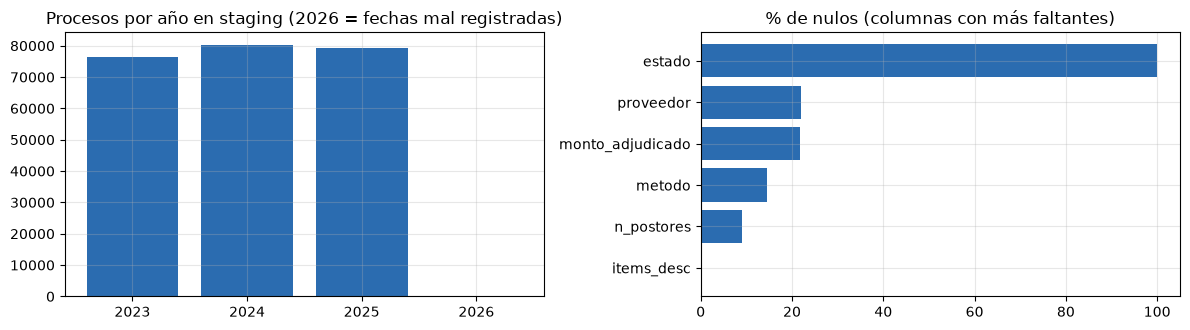

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].bar(vol["anio"].astype(str), vol["count"], color=["#2b6cb0"] * 3 + ["#c53030"])
ax[0].set_title("Procesos por año en staging (2026 = fechas mal registradas)")
ax[1].barh(nulos["columna"], nulos["pct_nulo"], color="#2b6cb0"); ax[1].set_title("% de nulos (columnas con más faltantes)")
mostrar_fig("datos")

- **Volumen:** 236,229 procesos en staging, ~76–80 mil por año; quedan 235,954 tras quitar 275 con fecha de 2026

- **Calidad:** `estado` 100% nulo, `proveedor` y `monto_adjudicado` faltan en ~22% y `n_postores` en ~9%

- **Inconsistencias:** 16,203 montos ≤ 0 (pasan a nulo) y 4,797 procesos en otra moneda (convertidos a soles)

- **Casi-duplicados:** 9,276 grupos con misma entidad, fecha, monto y descripción (8.8% de filas)

- **Transformaciones:** se agrega `shingles` (k=5), `tokens`, `postor_unico` y `canasta`

### 3. Técnicas y parámetros

| Sección | Técnica | Pregunta | Columna | Parámetros elegidos | Dónde corre |
|---|---|---|---|---|---|
| Similitud | MinHash + LSH | P2 | `shingles` | k=5, `T`=100, (b, r)=(10, 10), ventana 15 días, Jaccard ≥ 0.90 | Spark (joins por mes) |
| Vecinos | TF-IDF + IVF | P3 | `tokens` | 4,096 dims, `NLIST`=300, `NPROBE`=2, `K`=10, coseno ≥ 0.80 | Spark (KMeans + joins) |
| Vecinos | IVF / HNSW (faiss) | P3 | `tokens` | `M`=32, `efSearch`=16, 20k vectores | Python, sin Spark (faiss) |
| Flujos | DGIM | P1 | `postor_unico` | ventana ≈ 1 mes (6,600 llegadas), `r`=2 | Python, sin Spark (flujo secuencial) |
| Flujos | Bloom Filter | P1 | `entidad`, `proveedor` | 9.6 bits por par, `k`=7, FPR objetivo 1% | Python, sin Spark |
| Flujos | Count-Min Sketch | P1 | `entidad`, `proveedor` | `w`=33,390, `d`=5, heavy hitter ≥ 50 | Python, sin Spark |
| Asociacion | Apriori / FP-Growth | P1 | `canasta` | soporte 0.02, confianza 0.5 | Apriori con mlxtend (Q4 2025), FP-Growth en Spark (completo) |

### 4. Desempeño de las técnicas

Ahorro de cada técnica frente al cálculo exacto y cuánto error comete

In [6]:
def fila(tecnica, pregunta, ahorro, tipo_ahorro, metrica, error):
    return {"tecnica": tecnica, "pregunta": pregunta, "ahorro_x": round(ahorro, 1), "tipo_ahorro": tipo_ahorro,
            "metrica_error": metrica, "error": error}

lsh = leer("02_Similitud", "b_lsh", "configs_br").query("b == 10 and r == 10").iloc[0]
mh = leer("02_Similitud", "a_minhash", "resumen").iloc[0]
ann = leer("03_ANN", "e_analisis", "tecnicas").set_index("metodo")
flu = leer("04_Flujos", "d_analisis", "comparativa").set_index("estructura")
bf = leer("02_Similitud", "b_lsh", "resumen").iloc[0]

tecnicas_resumen = pd.DataFrame([
    fila("MinHash (T=100)", "P2", 1, "—", "error medio vs Jaccard", mh.mae_minhash),
    fila("LSH (10, 10)", "P2", bf.pares_fuerza_bruta / lsh.candidatos, "comparaciones", "recall", lsh.recall),
    fila("IVF propio (Spark)", "P3", ann.loc["IVF propio (Spark)", "aceleracion_vs_exacto"], "tiempo", "recall@10", ann.loc["IVF propio (Spark)", "recall_at_k"]),
    fila("IVF (faiss)", "P3", ann.loc["IVF (faiss)", "aceleracion_vs_exacto"], "tiempo", "recall@10", ann.loc["IVF (faiss)", "recall_at_k"]),
    fila("HNSW (faiss)", "P3", ann.loc["HNSW (faiss)", "aceleracion_vs_exacto"], "tiempo", "recall@10", ann.loc["HNSW (faiss)", "recall_at_k"]),
    *[fila(e, "P1", flu.loc[e, "ahorro_memoria"], "memoria", flu.loc[e, "metrica_error"], flu.loc[e, "error"]) for e in flu.index],
])
tecnicas_resumen["error"] = tecnicas_resumen["error"].round(4)
tecnicas_resumen

,tecnica,pregunta,ahorro_x,tipo_ahorro,metrica_error,error
0,MinHash (T=100),P2,1.0,—,error medio vs Jaccard,0.0314
1,"LSH (10, 10)",P2,20.3,comparaciones,recall,0.9999
2,IVF propio (Spark),P3,14.7,tiempo,recall@10,0.7500
3,IVF (faiss),P3,3.8,tiempo,recall@10,0.8923
4,HNSW (faiss),P3,20.9,tiempo,recall@10,0.9799
5,DGIM,P1,20.4,memoria,error relativo medio,0.1089
6,Bloom Filter,P1,135.0,memoria,tasa de falsos positivos (final),0.0102
7,Count-Min Sketch,P1,34.7,memoria,sobreestimación media (apariciones),1.9812


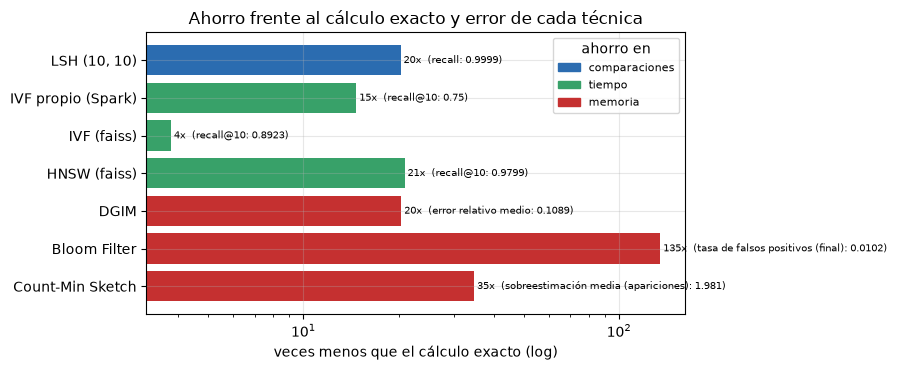

In [7]:
t = tecnicas_resumen[tecnicas_resumen["tipo_ahorro"] != "—"].iloc[::-1]
colores = {"comparaciones": "#2b6cb0", "tiempo": "#38a169", "memoria": "#c53030"}
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(t["tecnica"], t["ahorro_x"], color=[colores[c] for c in t["tipo_ahorro"]])
for y_, (v, m, e) in enumerate(zip(t["ahorro_x"], t["metrica_error"], t["error"])):
    ax.annotate(f" {v:,.0f}x  ({m}: {e:.4g})", (v, y_), va="center", fontsize=7)
ax.set_xscale("log"); ax.set_xlabel("veces menos que el cálculo exacto (log)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c_) for c_ in colores.values()], labels=list(colores), title="ahorro en", fontsize=8, loc="upper right"); ax.set_title("Ahorro frente al cálculo exacto y error de cada técnica")
mostrar_fig("desempeno_tecnicas")

- **Similitud:** LSH revisa 20x menos pares que la fuerza bruta (163k vs 3.3M) y solo pierde 9 de 131,482 pares

- **Vecinos:** el IVF propio en Spark es 14.7x más rápido con recall de 75%; en faiss, HNSW llega a 98% con 21x

- **Flujos:** Bloom ahorra 135x de memoria con 1% de falsos positivos, 

- **Flujos**: Count-Min 35x con 2 apariciones de sobreestimación y DGIM 20x con 11% de error

- **Reglas:** FP-Growth en Spark procesa los 236k procesos

### 5. Escritura de resultados

Tablas en `temp/a_recuento/tablas` y `web/`

In [11]:
tablas = {"tecnicas_resumen": tecnicas_resumen}
escritos = {nombre: guardar_tabla(df, nombre) for nombre, df in tablas.items()}
print(f"Escrito en temp/a_recuento/: {', '.join(escritos)}")

Escrito en temp/a_recuento/: tecnicas_resumen


#### a. Verificación

In [12]:
for nombre, n in escritos.items():
    leido = spark.read.parquet(str(tab_dir / nombre)).count()
    assert leido == n, f"{nombre}: esperaba {n}, leí {leido}"
    assert (web_dir / f"{nombre}.json").exists(), f"falta web/{nombre}.json"

figs = sorted(p.stem for p in fig_dir.glob("*.png"))
print(f"OK: {len(escritos)} tablas (parquet + json) | {len(figs)} figuras: {', '.join(figs)}")

OK: 1 tablas (parquet + json) | 2 figuras: datos, desempeno_tecnicas


---
### 6. Cerrar sesión

In [8]:
spark.stop()